# Carbon (CO₂) Emissions Data Analysis

### Importing Libraries

In [7]:
import os
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline  # Importing the interpolation function
%matplotlib inline

In [11]:
Emission_Data = pd.read_csv(r"C:\Users\hp\Desktop\python\Carbon (CO2) Emissions\Carbon_(CO2)_Emissions_by_Country.csv")
Emission_Data.head()

,Country,Region,Date,Kilotons of Co2,Metric Tons Per Capita
0,Afghanistan,Asia,01-01-2011,8930.0,0.31
1,Afghanistan,Asia,01-01-2012,8080.0,0.27
2,Afghanistan,Asia,01-01-2010,7110.0,0.25
3,Afghanistan,Asia,01-01-2019,6080.0,0.16
4,Afghanistan,Asia,01-01-2018,6070.0,0.17


In [13]:
Emission_Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5677 entries, 0 to 5676
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country                 5677 non-null   object 
 1   Region                  5677 non-null   object 
 2   Date                    5677 non-null   object 
 3   Kilotons of Co2         5677 non-null   float64
 4   Metric Tons Per Capita  5677 non-null   float64
dtypes: float64(2), object(3)
memory usage: 221.9+ KB


In [15]:
Emission_Data['Date'] = pd.to_datetime(Emission_Data['Date'], errors='coerce')
Emission_Data['year'] = Emission_Data['Date'].dt.year
Emission_Data.dtypes

Country                           object
Region                            object
Date                      datetime64[ns]
Kilotons of Co2                  float64
Metric Tons Per Capita           float64
year                               int32
dtype: object

In [19]:
Emission_Data.drop_duplicates()
print(Emission_Data.duplicated().sum())

0


In [21]:
Emission_Data.isnull().any()
#if any is null then:
#Emission_Data.isnull().sum()

Country                   False
Region                    False
Date                      False
Kilotons of Co2           False
Metric Tons Per Capita    False
year                      False
dtype: bool

In [23]:
# Function to categorize the year
def categorize_year(year):
    if 1940 <= year <= 1950:
        return '1940-1950'
    elif 1951 <= year <= 1960:
        return '1951-1960'
    elif 1961 <= year <= 1970:
        return '1961-1970'
    elif 1971 <= year <= 1980:
        return '1971-1980'
    elif 1981 <= year <= 1990:
        return '1981-1990'
    elif 1991 <= year <= 2000:
        return '1991-2000'
    elif 2001 <= year <= 2010:
        return '2001-2010'    
    elif 2011 <= year <= 2020:
        return '2011-2020'
    else:
        return 'Current-decade'  # or some other label for years outside the specified range

In [27]:
# Create a new column using apply
Emission_Data['decade'] = Emission_Data['year'].apply(categorize_year)

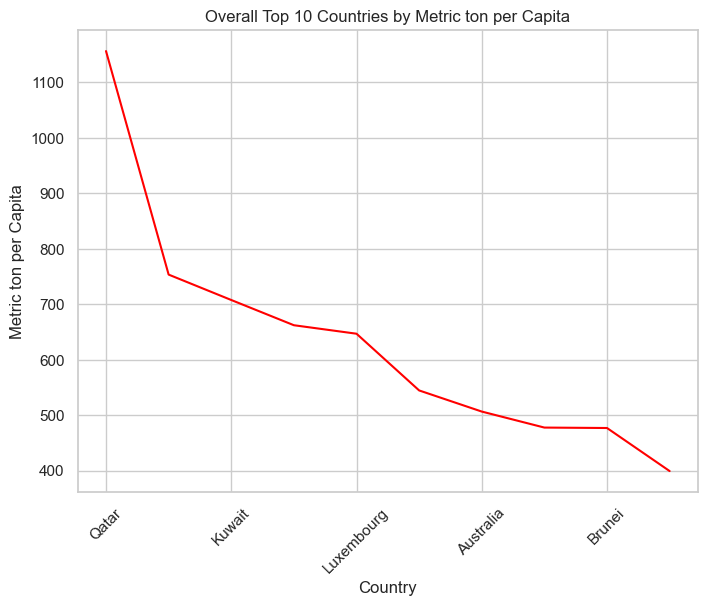

In [74]:
Top_10_countries = Emission_Data.groupby("Country")["Metric Tons Per Capita"].sum().sort_values(ascending=False).head(10)

# Set the visual style of the plots
sns.set(style="whitegrid")

# plotting top 10 countries with the most confirmed cases:
Top_10_countries.plot(kind='line', figsize=(8, 6), color='red')
plt.title("Overall Top 10 Countries by Metric ton per Capita")
plt.xlabel("Country")
plt.ylabel("Metric ton per Capita")
plt.xticks(rotation=45)
plt.show()

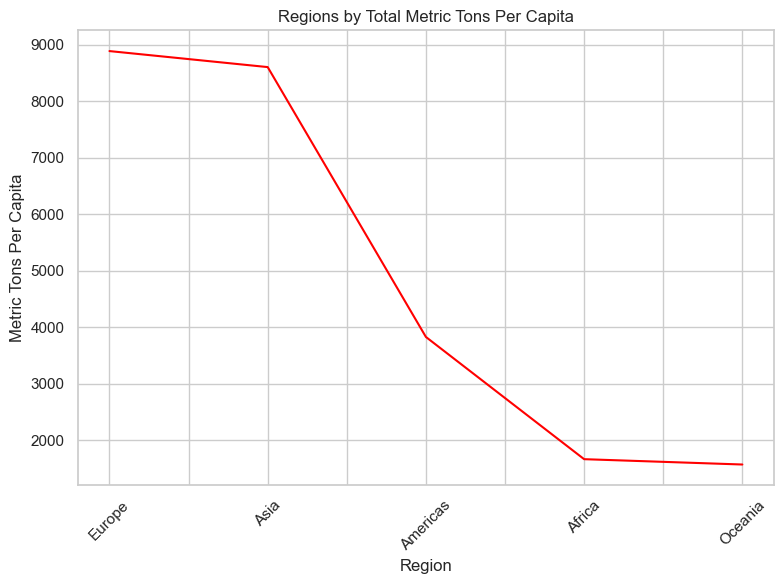

In [76]:
# Group by Region and calculate the total Metric Tons Per Capita
Top_Regions = (
    Emission_Data.groupby("Region")["Metric Tons Per Capita"]
    .sum()
    .sort_values(ascending=False)
)

# Plot the bar chart
plt.figure(figsize=(8, 6))
Top_Regions.plot(kind='line', color='red')

plt.title("Regions by Total Metric Tons Per Capita")
plt.xlabel("Region")
plt.ylabel("Metric Tons Per Capita")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

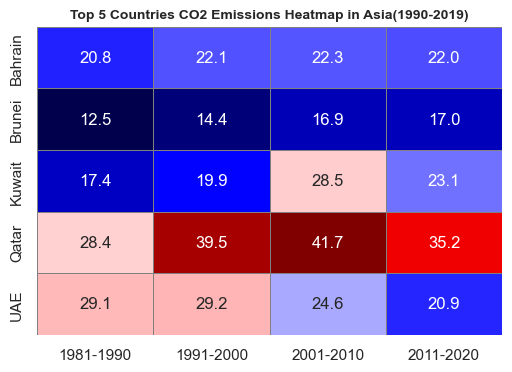

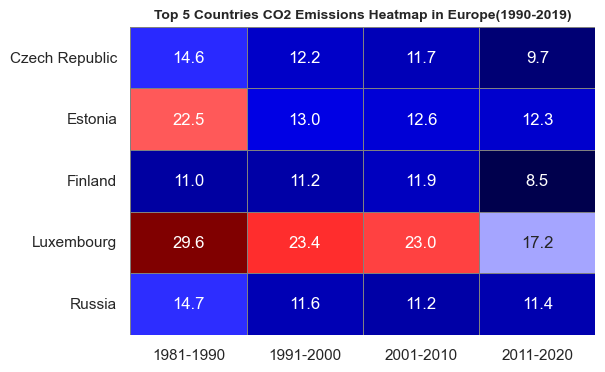

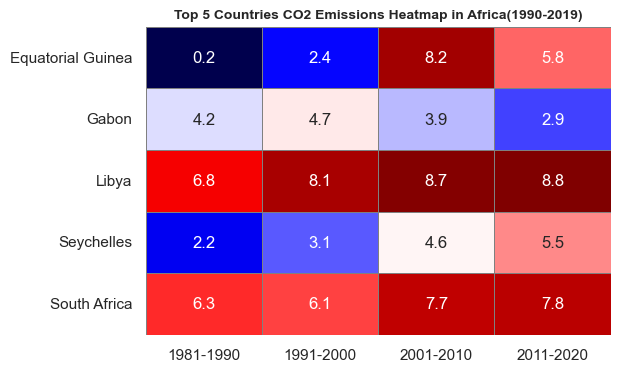

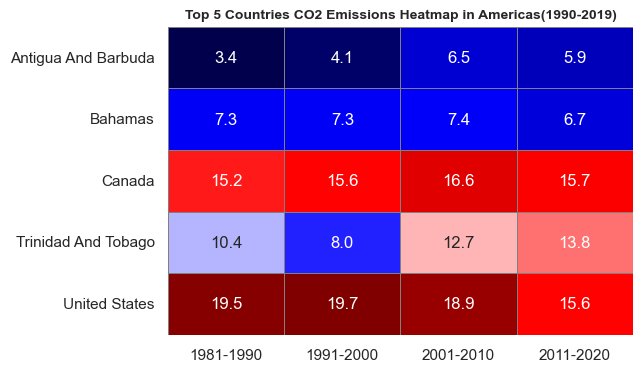

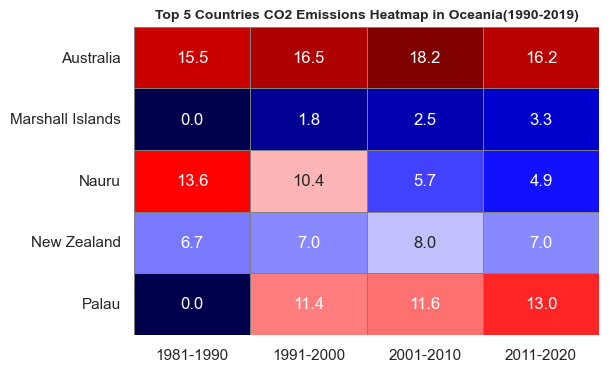

In [80]:
# Define a function to plot the heatmap for top 5 countries in each region
def plot_heatmap_for_regions():
    # Get distinct regions from the dataset
    regions = Emission_Data['Region'].unique()
    
    # Extract the minimum and maximum years for the overall title
    min_year_title = Emission_Data['year'].min()
    max_year_title = Emission_Data['year'].max()
    
    # Set the visual style
    sns.set(style="white")

    # Loop through each region and create a heatmap
    for region in regions:

        # Filter the data for the current region
        filtered_df = Emission_Data[Emission_Data['Region'] == region]

        # Step 1: Calculate the average Metric Tons Per Capita for each country
        country_avg_metric = filtered_df.groupby('Country')['Metric Tons Per Capita'].mean().reset_index()

        # Step 2: Select the top 5 countries based on average emissions
        top_countries = country_avg_metric.nlargest(5, 'Metric Tons Per Capita')['Country']

        # Step 3: Filter the main data to include only the top 5 countries
        filtered_df_top_countries = filtered_df[filtered_df['Country'].isin(top_countries)]

        # Create a pivot table for heatmap using mean
        heatmap_data = filtered_df_top_countries.pivot_table(
            index='Country',
            columns='decade',
            values='Metric Tons Per Capita',
            aggfunc='mean',  # Use mean instead of sum
            fill_value=0  # Handle NaN values
        )

        # Round values up to 1 decimal place
        heatmap_data = np.ceil(heatmap_data * 10) / 10

        # Create the heatmap
        plt.figure(figsize=(6, 4))
        ax = sns.heatmap(
            heatmap_data,
            cmap='seismic',
            annot=True,  # Show values in the heatmap
            fmt=".1f",  # Format for displaying the numbers
            cbar=False,
            linewidths=0.5,
            linecolor='gray'
        )

        # Set titles and labels
        plt.title(f"Top 5 Countries CO2 Emissions Heatmap in {region}({min_year_title}-{max_year_title})", fontsize=10, fontweight='bold')
        ax.set_xlabel("")  # Clear x-axis label
        ax.set_ylabel("")  # Clear y-axis label

        # Show the plot for the current region
        plt.show()

# Example usage: Plotting heatmaps for all regions
plot_heatmap_for_regions()

C:\Users\hp\AppData\Local\Temp\ipykernel_18672\847831062.py:51: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
C:\Users\hp\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


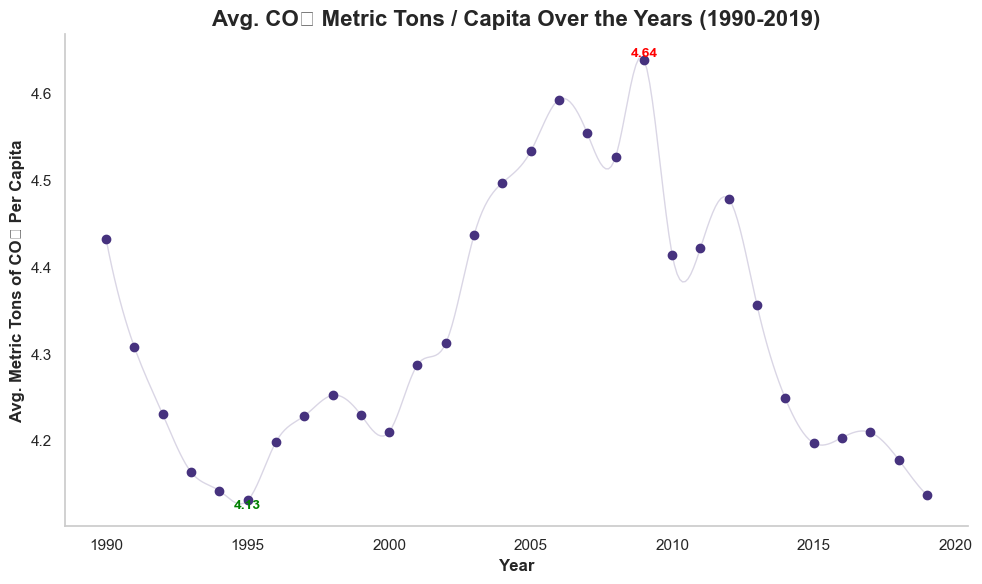

In [40]:
# Calculate the average Metric Tons Per Capita by year across all countries
overall_decade_avg_metric = Emission_Data.groupby('year', as_index=False)['Metric Tons Per Capita'].mean()

# Extract the minimum and maximum years for the overall title
min_year_title = Emission_Data['year'].min()
max_year_title = Emission_Data['year'].max()

# Convert any infinite values to NaN
overall_decade_avg_metric.replace([np.inf, -np.inf], np.nan, inplace=True)

# Drop rows with NaN values to ensure clean data
overall_decade_avg_metric.dropna(inplace=True)

# Set the visual style of the plot without grid
sns.set(style="whitegrid", rc={"axes.grid": False})  # Disable grid lines

# Create a smooth line using spline interpolation
x = overall_decade_avg_metric['year']
y = overall_decade_avg_metric['Metric Tons Per Capita']
x_smooth = np.linspace(x.min(), x.max(), 300)  # More points for smoothness
spline = make_interp_spline(x, y, k=3)  # Cubic spline interpolation
y_smooth = spline(x_smooth)

# Create a line plot for average CO₂ Metric Tons Per Capita over years with curves
plt.figure(figsize=(10, 6))
plt.plot(x_smooth, y_smooth, color=sns.color_palette("viridis")[0], linewidth=1, alpha=0.2)  # Use Viridis color
plt.scatter(x, y, color=sns.color_palette("viridis")[0])  # Add original data points for reference

# Highlighting maximum and minimum points
max_value = overall_decade_avg_metric['Metric Tons Per Capita'].max()
min_value = overall_decade_avg_metric['Metric Tons Per Capita'].min()
max_year = overall_decade_avg_metric[overall_decade_avg_metric['Metric Tons Per Capita'] == max_value]['year'].values[0]
min_year = overall_decade_avg_metric[overall_decade_avg_metric['Metric Tons Per Capita'] == min_value]['year'].values[0]

# Adding data labels for maximum and minimum values
plt.text(max_year, max_value, f'{max_value:.2f}', color='red', fontsize=10, ha='center', va='bottom', fontweight='bold')
plt.text(min_year, min_value, f'{min_value:.2f}', color='green', fontsize=10, ha='center', va='top', fontweight='bold')

# Set titles and labels
plt.title(f"Avg. CO₂ Metric Tons / Capita Over the Years ({min_year_title}-{max_year_title})", fontsize=16, fontweight='bold')
plt.xlabel("Year", fontweight='bold')  # Update the x-axis title
plt.ylabel("Avg. Metric Tons of CO₂ Per Capita", fontweight='bold')  # Update the y-axis title

# Remove borders (spines)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)

# Adjust layout for better appearance
plt.tight_layout()

# Show the plot
plt.show()

In [86]:
# List of G7 countries
g7_countries = ['Canada','France','Germany','Italy','Japan','United Kingdom','United States']

# Creating a new column
Emission_Data['Country Group(G7)'] = Emission_Data['Country'].apply(
    lambda x: 'G7' if x in g7_countries else 'Other Countries')

g7_summary = (Emission_Data.groupby('Country Group(G7)')['Metric Tons Per Capita'].sum().sort_values(ascending=True))
print(g7_summary)

Country Group(G7)
G7                  2218.53
Other Countries    22337.36
Name: Metric Tons Per Capita, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_18672\673556975.py:62: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()  # Increased padding for better spacing
C:\Users\hp\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


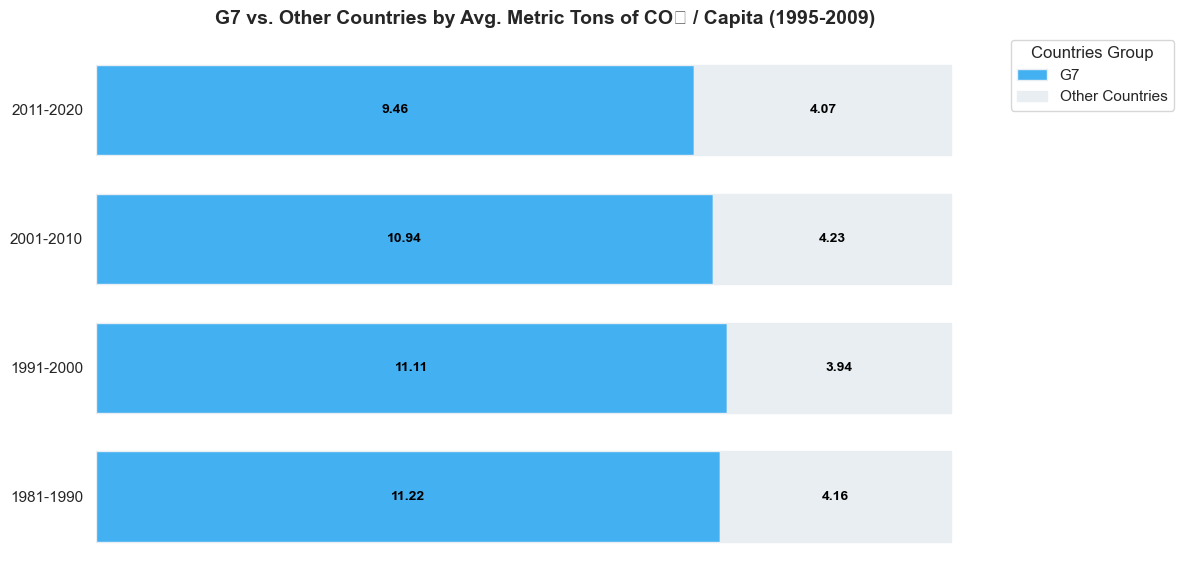

In [50]:
# Calculate the average Metric Tons Per Capita by decade and country
country_decade_avg_metric = Emission_Data.groupby(['decade', 'Country Group(G7)'], as_index=False)['Metric Tons Per Capita'].mean()

# Calculate the total Metric Tons Per Capita for each decade
decade_totals = country_decade_avg_metric.groupby('decade')['Metric Tons Per Capita'].sum().reset_index()
decade_totals.rename(columns={'Metric Tons Per Capita': 'Total Per Decade'}, inplace=True)

# Merge the total with the original dataset to calculate percentage
country_decade_avg_metric = country_decade_avg_metric.merge(decade_totals, on='decade')
country_decade_avg_metric['Percentage'] = (
    country_decade_avg_metric['Metric Tons Per Capita'] / country_decade_avg_metric['Total Per Decade']
) * 100

# Pivot the data for a stacked bar chart
stacked_data = country_decade_avg_metric.pivot(
    index='decade', columns='Country Group(G7)', values='Percentage'
).fillna(0)

# Also pivot to retrieve the actual average CO₂ emissions for annotation
emission_data = country_decade_avg_metric.pivot(
    index='decade', columns='Country Group(G7)', values='Metric Tons Per Capita'
).fillna(0)

# Set the visual style of the plots
sns.set(style="whitegrid")

# Plot the horizontal 100% stacked bar chart
ax = stacked_data.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6),
    width=0.7,
    color=['#43b0f1', '#e8eef1'],
    edgecolor='#e8eef1'
)

# Remove grid lines
ax.grid(False)

# Remove x-axis labels
ax.set_xticklabels([])

for spine in ['top', 'right','bottom','left']:
    ax.spines[spine].set_visible(False)

# Add data labels for each segment
for i, (decade, row) in enumerate(emission_data.iterrows()):  # Loop through rows (decades)
    cumulative_percentage = 0  # To track where each segment starts on the x-axis
    for group, value in row.items():  # Loop through each country group (legend)
        if value > 0:  # Only add labels for non-zero values
            cumulative_percentage += stacked_data.loc[decade, group]
            ax.text(
                cumulative_percentage - stacked_data.loc[decade, group] / 2,  # Middle of the segment
                i,  # Corresponding bar position
                f"{value:.2f}",  # Format as "XX.XX"
                va='center', ha='center', fontsize=10, color='black', fontweight='bold'
            )

plt.title(f"G7 vs. Other Countries by Avg. Metric Tons of CO₂ / Capita ({min_year}-{max_year})", fontsize=14, fontweight='bold')
plt.ylabel("")
plt.legend(title="Countries Group", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()  # Increased padding for better spacing

# Display the plot
plt.show()

In [52]:
# List of G20 countries
g20_countries  = ['United States','China','Japan','Germany','India','United Kingdom',
                 'Brazil','Italy','Canada','Russia','France',
                 'Australia','South Korea','Mexico','Indonesia','Saudi Arabia','Turkey',
                 'Argentina','South Africa']

# Creating a new column
Emission_Data['Country Group(G20)'] = Emission_Data['Country'].apply(lambda x: 'G20' if x in g20_countries else 'Other Countries')

C:\Users\hp\AppData\Local\Temp\ipykernel_18672\831944132.py:62: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()  # Increased padding for better spacing
C:\Users\hp\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


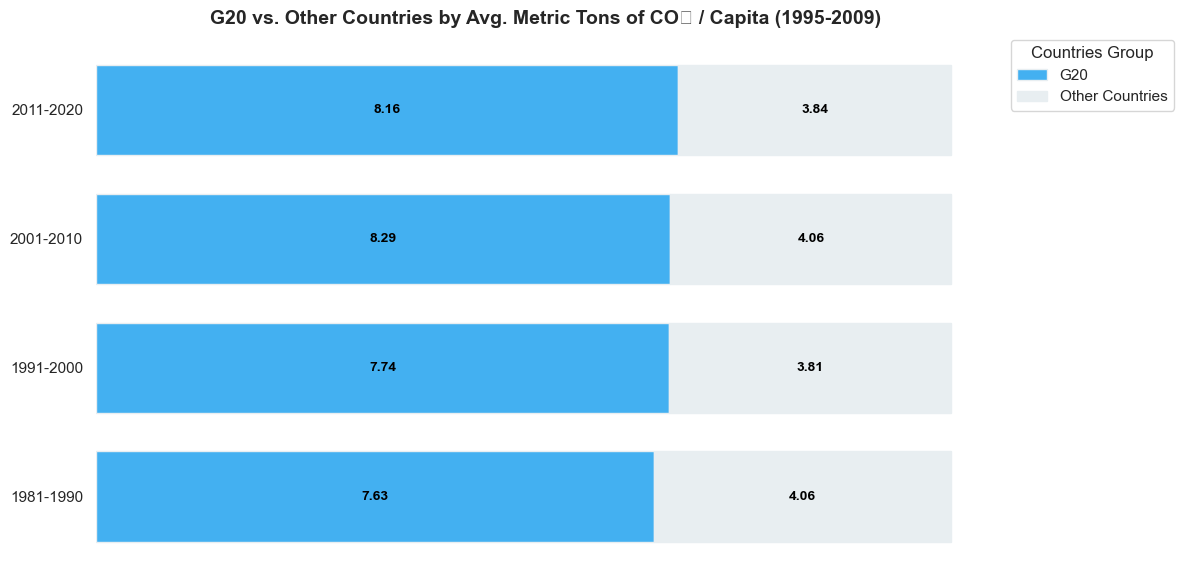

In [54]:
# Calculate the average Metric Tons Per Capita by decade and country
country_decade_avg_metric = Emission_Data.groupby(['decade', 'Country Group(G20)'], as_index=False)['Metric Tons Per Capita'].mean()

# Calculate the total Metric Tons Per Capita for each decade
decade_totals = country_decade_avg_metric.groupby('decade')['Metric Tons Per Capita'].sum().reset_index()
decade_totals.rename(columns={'Metric Tons Per Capita': 'Total Per Decade'}, inplace=True)

# Merge the total with the original dataset to calculate percentage
country_decade_avg_metric = country_decade_avg_metric.merge(decade_totals, on='decade')
country_decade_avg_metric['Percentage'] = (
    country_decade_avg_metric['Metric Tons Per Capita'] / country_decade_avg_metric['Total Per Decade']
) * 100

# Pivot the data for a stacked bar chart
stacked_data = country_decade_avg_metric.pivot(
    index='decade', columns='Country Group(G20)', values='Percentage'
).fillna(0)

# Also pivot to retrieve the actual average CO₂ emissions for annotation
emission_data = country_decade_avg_metric.pivot(
    index='decade', columns='Country Group(G20)', values='Metric Tons Per Capita'
).fillna(0)

# Set the visual style of the plots
sns.set(style="whitegrid")

# Plot the horizontal 100% stacked bar chart
ax = stacked_data.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6),
    width=0.7,
    color=['#43b0f1', '#e8eef1'],
    edgecolor='#e8eef1'
)

# Remove grid lines
ax.grid(False)

# Remove x-axis labels
ax.set_xticklabels([])

for spine in ['top', 'right','bottom','left']:
    ax.spines[spine].set_visible(False)

# Add data labels for each segment
for i, (decade, row) in enumerate(emission_data.iterrows()):  # Loop through rows (decades)
    cumulative_percentage = 0  # To track where each segment starts on the x-axis
    for group, value in row.items():  # Loop through each country group (legend)
        if value > 0:  # Only add labels for non-zero values
            cumulative_percentage += stacked_data.loc[decade, group]
            ax.text(
                cumulative_percentage - stacked_data.loc[decade, group] / 2,  # Middle of the segment
                i,  # Corresponding bar position
                f"{value:.2f}",  # Format as "XX.XX"
                va='center', ha='center', fontsize=10, color='black', fontweight='bold'
            )

plt.title(f"G20 vs. Other Countries by Avg. Metric Tons of CO₂ / Capita ({min_year}-{max_year})", fontsize=14, fontweight='bold')
plt.ylabel("")
plt.legend(title="Countries Group", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()  # Increased padding for better spacing

# Display the plot
plt.show()

In [90]:
# List of African countries
african_countries = [
    'Algeria', 'Angola', 'Benin', 'Botswana', 'Burkina Faso',
    'Burundi', 'Cabo Verde', 'Cameroon', 'Central African Republic',
    'Chad', 'Comoros', 'Congo', 'Democratic Republic of the Congo',
    'Djibouti', 'Egypt', 'Equatorial Guinea', 'Eritrea', 'Eswatini',
    'Ethiopia', 'Gabon', 'Gambia', 'Ghana', 'Guinea',
    'Guinea-Bissau', 'Ivory Coast', 'Kenya', 'Lesotho', 'Liberia',
    'Libya', 'Madagascar', 'Malawi', 'Mali', 'Mauritania',
    'Mauritius', 'Morocco', 'Mozambique', 'Namibia', 'Niger',
    'Nigeria', 'Rwanda', 'Sao Tome and Principe', 'Senegal',
    'Seychelles', 'Sierra Leone', 'Somalia', 'South Africa',
    'South Sudan', 'Sudan', 'Tanzania', 'Togo', 'Tunisia',
    'Uganda', 'Zambia', 'Zimbabwe']

# Create a new column
Emission_Data['Country Group(Africa)'] = Emission_Data['Country'].apply(
    lambda x: 'Africa' if x in african_countries else 'Other Regions'
)

# Summary
africa_summary = Emission_Data.groupby('Country Group(Africa)')['Metric Tons Per Capita'].mean().sort_values(ascending=False)
print(africa_summary)

Country Group(Africa)
Other Regions    5.484802
Africa           1.082575
Name: Metric Tons Per Capita, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_18672\3048663462.py:77: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()
C:\Users\hp\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


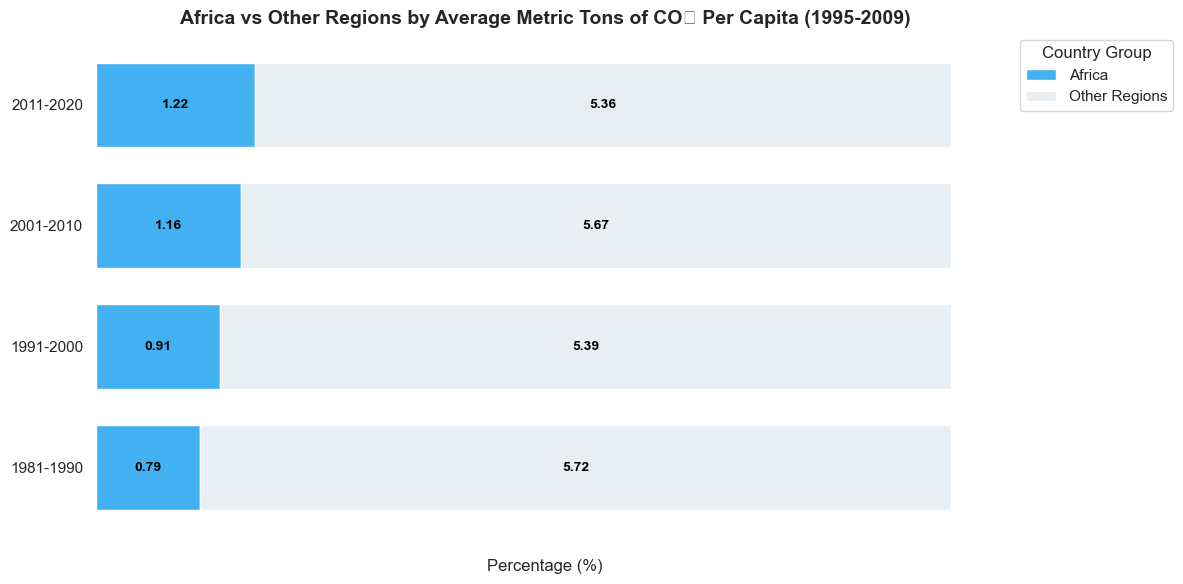

In [98]:
# Calculate the average Metric Tons Per Capita by decade and country group
Africans_decade_avg_metric = (Emission_Data.groupby(['decade', 'Country Group(Africa)'], as_index=False)['Metric Tons Per Capita'].mean())

# Calculate the total average Metric Tons Per Capita for each decade
decade_totals = (Africans_decade_avg_metric.groupby('decade')['Metric Tons Per Capita'].sum().reset_index())
decade_totals.rename(columns={'Metric Tons Per Capita': 'Total Per Decade'}, inplace=True)

# Merge totals with grouped data
Africans_decade_avg_metric = Africans_decade_avg_metric.merge(decade_totals,on='decade')

# Calculate percentage contribution
Africans_decade_avg_metric['Percentage'] = (
    Africans_decade_avg_metric['Metric Tons Per Capita']
    / Africans_decade_avg_metric['Total Per Decade']
) * 100

# Pivot for stacked bar chart
stacked_data = Africans_decade_avg_metric.pivot(
    index='decade',
    columns='Country Group(Africa)',
    values='Percentage'
).fillna(0)

# Pivot for annotations
emission_data = Africans_decade_avg_metric.pivot(
    index='decade',
    columns='Country Group(Africa)',
    values='Metric Tons Per Capita'
).fillna(0)

# Set plot style
sns.set(style="whitegrid")

# Plot horizontal 100% stacked bar chart
ax = stacked_data.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6),
    width=0.7,
    color=['#43b0f1', '#e8eef1'],
    edgecolor='white'
)

# Remove grid and spines
ax.grid(False)
ax.set_xticklabels([])

for spine in ['top', 'right', 'bottom', 'left']:
    ax.spines[spine].set_visible(False)

# Add data labels
for i, (decade, row) in enumerate(emission_data.iterrows()):
    cumulative_percentage = 0
    for group, value in row.items():
        if value > 0:
            cumulative_percentage += stacked_data.loc[decade, group]
            ax.text(
                cumulative_percentage - stacked_data.loc[decade, group] / 2,
                i,
                f"{value:.2f}",
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold',
                color='black'
            )

plt.title(
    f"Africa vs Other Regions by Average Metric Tons of CO₂ Per Capita ({min_year}-{max_year})",
    fontsize=14,
    fontweight='bold')

plt.xlabel("Percentage (%)")
plt.ylabel("")
plt.legend(title="Country Group",bbox_to_anchor=(1.02, 1),loc="upper left")

plt.tight_layout()
plt.show()

C:\Users\hp\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\hp\AppData\Local\Temp\ipykernel_18672\1188837845.py:61: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout(rect=[0, 0, 1, 0.96])
C:\Users\hp\AppData\Local\Temp\ipykernel_18672\1188837845.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0, 1, 0.96])
C:\Users\hp\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


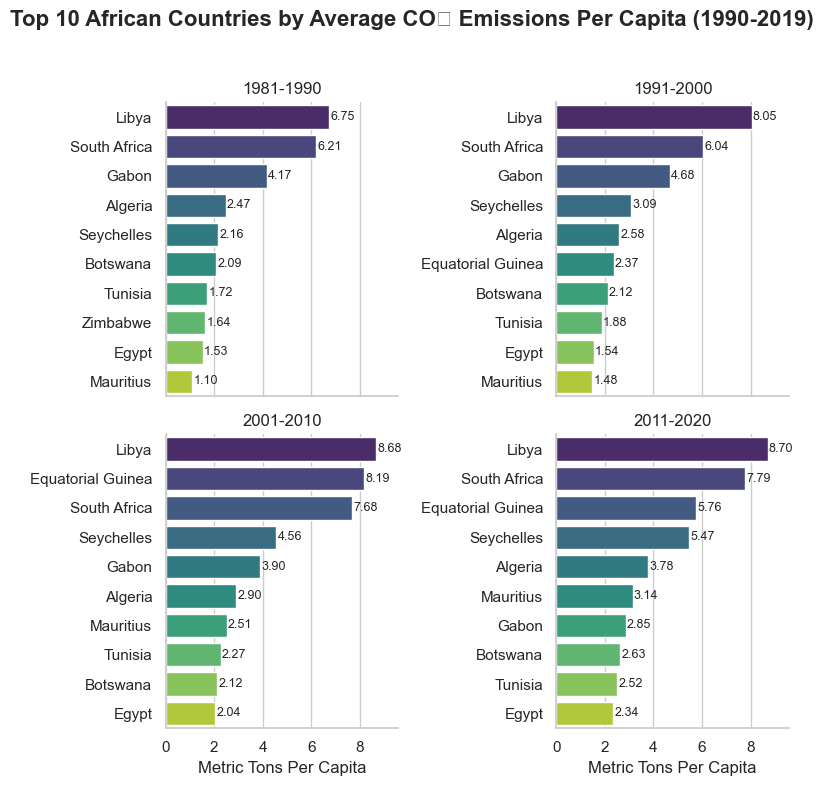

In [106]:
# Keep only African countries
africa_df = Emission_Data[Emission_Data['Country Group(Africa)'] == 'Africa']

# Average emissions by decade and country
country_decade_avg_metric = (africa_df.groupby(['decade', 'Country'], as_index=False)['Metric Tons Per Capita'].mean())

# Top 10 countries for each decade
top_african_countries = (country_decade_avg_metric.groupby('decade', group_keys=False)
                         .apply(lambda x: x.nlargest(10, 'Metric Tons Per Capita'))
                         .reset_index(drop=True))

# Extract the minimum and maximum years
min_year = africa_df['Date'].dt.year.min()
max_year = africa_df['Date'].dt.year.max()

# Create a FacetGrid (one chart per decade)
g = sns.FacetGrid(top_african_countries,col='decade',col_wrap=2,height=4,sharex=True,sharey=False)

# Draw the bar charts
g.map_dataframe(sns.barplot,x='Metric Tons Per Capita',y='Country',palette='viridis')

# Customize each subplot
for ax, decade in zip(g.axes.flat, sorted(top_african_countries['decade'].unique())):
    decade_data = (
        top_african_countries[top_african_countries['decade'] == decade]
        .sort_values('Metric Tons Per Capita', ascending=False))
    ax.set_title(f"Top 10 African Countries ({decade})",fontweight='bold')
    ax.set_xlim(0,top_african_countries['Metric Tons Per Capita'].max() * 1.10)

# Add value labels
    for i, value in enumerate(decade_data['Metric Tons Per Capita']):
        ax.text(value + 0.05,i,f"{value:.2f}",va='center',fontsize=9)

# Overall title
plt.suptitle(
    f"Top 10 African Countries by Average CO₂ Emissions Per Capita ({min_year}-{max_year})",
    fontsize=16,
    fontweight='bold'
)

# Axis labels
g.set_axis_labels("Metric Tons Per Capita", "")
g.set_titles(col_template="{col_name}")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [110]:
# List of European Union countries
eu_countries  = ['Belgium','Bulgaria','Denmark','Germany','Estonia','Ireland','Greece',
                 'Spain','France','Croatia','Italy','Cyprus','Latvia','Lithuania','Luxembourg',
                 'Hungary','Malta','Netherlands','Austria','Poland','Portugal','Romania',
                 'Slovak Republic','Slovenia','Finland','Czech Republic','Sweden']


# Creating a new column
Emission_Data['Country Group(EU)'] = Emission_Data['Country'].apply(lambda x: 'EU' if x in eu_countries else 'Other Countries')

C:\Users\hp\AppData\Local\Temp\ipykernel_18672\1757162827.py:62: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  plt.tight_layout()  # Increased padding for better spacing
C:\Users\hp\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


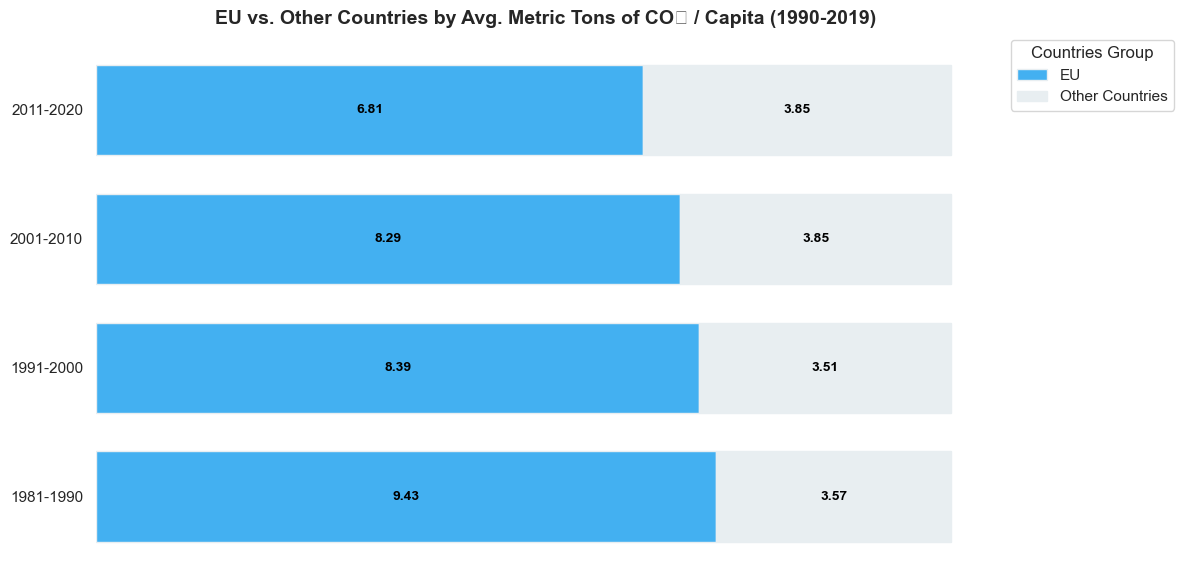

In [112]:
# Calculate the average Metric Tons Per Capita by decade and country
country_decade_avg_metric = Emission_Data.groupby(['decade', 'Country Group(EU)'], as_index=False)['Metric Tons Per Capita'].mean()

# Calculate the total Metric Tons Per Capita for each decade
decade_totals = country_decade_avg_metric.groupby('decade')['Metric Tons Per Capita'].sum().reset_index()
decade_totals.rename(columns={'Metric Tons Per Capita': 'Total Per Decade'}, inplace=True)

# Merge the total with the original dataset to calculate percentage
country_decade_avg_metric = country_decade_avg_metric.merge(decade_totals, on='decade')
country_decade_avg_metric['Percentage'] = (
    country_decade_avg_metric['Metric Tons Per Capita'] / country_decade_avg_metric['Total Per Decade']
) * 100

# Pivot the data for a stacked bar chart
stacked_data = country_decade_avg_metric.pivot(
    index='decade', columns='Country Group(EU)', values='Percentage'
).fillna(0)

# Also pivot to retrieve the actual average CO₂ emissions for annotation
emission_data = country_decade_avg_metric.pivot(
    index='decade', columns='Country Group(EU)', values='Metric Tons Per Capita'
).fillna(0)

# Set the visual style of the plots
sns.set(style="whitegrid")

# Plot the horizontal 100% stacked bar chart
ax = stacked_data.plot(
    kind='barh',
    stacked=True,
    figsize=(12, 6),
    width=0.7,
    color=['#43b0f1', '#e8eef1'],
    edgecolor='#e8eef1'
)

# Remove grid lines
ax.grid(False)

# Remove x-axis labels
ax.set_xticklabels([])

for spine in ['top','right','bottom','left']:
    ax.spines[spine].set_visible(False)

# Add data labels for each segment
for i, (decade, row) in enumerate(emission_data.iterrows()):  # Loop through rows (decades)
    cumulative_percentage = 0  # To track where each segment starts on the x-axis
    for group, value in row.items():  # Loop through each country group (legend)
        if value > 0:  # Only add labels for non-zero values
            cumulative_percentage += stacked_data.loc[decade, group]
            ax.text(
                cumulative_percentage - stacked_data.loc[decade, group] / 2,  # Middle of the segment
                i,  # Corresponding bar position
                f"{value:.2f}",  # Format as "XX.XX"
                va='center', ha='center', fontsize=10, color='black', fontweight='bold'
            )

plt.title(f"EU vs. Other Countries by Avg. Metric Tons of CO₂ / Capita ({min_year}-{max_year})", fontsize=14, fontweight='bold')
plt.ylabel("")
plt.legend(title="Countries Group", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()  # Increased padding for better spacing

# Display the plot
plt.show()